# Day 3: Predict a Category | Diabetes Classification

**Objective:** Train and compare at least three classifiers to predict the binary `diabetes` label (0 or 1) from the supplied dataset. Evaluate **accuracy, precision, recall, F1-score**, and a **confusion matrix** for the best model. ROC-AUC is included as an optional metric.

**Educational exercise only:** These models are not validated clinical diagnostic tools and should not be used for medical decisions.

**Run instructions:** Upload `diabetes_prediction_dataset.csv` in the same Colab session as this notebook, or place the CSV in the notebook's current directory. Then choose **Runtime → Run all**. In Kaggle, use **Add Input** and update the CSV path in the loading cell.

## 1. Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, roc_auc_score,
    classification_report
)


## 2. Load dataset and perform basic EDA

In [2]:
df = pd.read_csv('diabetes_prediction_dataset.csv')
print('Original dataset shape:', df.shape)
display(df.head())
print('\nColumn information:')
df.info()
print('\nMissing values by column:')
display(df.isnull().sum().to_frame('Missing values'))
print('\nExact duplicate rows:', df.duplicated().sum())

Original dataset shape: (100000, 9)


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0



Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB

Missing values by column:


,Missing values
gender,0
age,0
hypertension,0
heart_disease,0
smoking_history,0
bmi,0
HbA1c_level,0
blood_glucose_level,0
diabetes,0



Exact duplicate rows: 3854


In [3]:
# Remove exact duplicate rows before splitting, reducing the chance of duplicate leakage.
df = df.drop_duplicates().copy()
assert df['diabetes'].dropna().isin([0, 1]).all(), 'Expected a binary target.'
print('Shape after duplicate removal:', df.shape)
print('\nClass distribution (0 = No, 1 = Yes):')
display(pd.DataFrame({
    'Count': df['diabetes'].value_counts().sort_index(),
    'Percent': (df['diabetes'].value_counts(normalize=True).sort_index() * 100).round(2)
}))

Shape after duplicate removal: (96146, 9)

Class distribution (0 = No, 1 = Yes):


,Count,Percent
diabetes,,
0,87664,91.18
1,8482,8.82


**Class imbalance:** The positive class is much less common than the negative class. Accuracy alone can be misleading, so we compare precision, recall, and especially F1-score for class `1`. The scoring choice is for this assignment, not a clinical decision rule.

## 3. Choose features and target, then split into training/test sets

In [4]:
X = df.drop(columns=['diabetes'])
y = df['diabetes']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

categorical_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()
numeric_cols = X.select_dtypes(include=np.number).columns.tolist()
print('Categorical features:', categorical_cols)
print('Numeric features:', numeric_cols)
print('Training shape:', X_train.shape, '| Test shape:', X_test.shape)
print('Positive class proportion (train/test):', round(y_train.mean(), 4), round(y_test.mean(), 4))

Categorical features: ['gender', 'smoking_history']
Numeric features: ['age', 'hypertension', 'heart_disease', 'bmi', 'HbA1c_level', 'blood_glucose_level']
Training shape: (76916, 8) | Test shape: (19230, 8)
Positive class proportion (train/test): 0.0882 0.0882


## 4. Preprocess data and train three classifiers

We apply one-hot encoding for text categories and standardization for numerical values. The transformations are **fit only on training data** through Scikit-learn pipelines, preventing test-data leakage. The same feature engineering is used for all models.

In [5]:
def make_preprocessor():
    return ColumnTransformer(transformers=[
        ('numeric', StandardScaler(), numeric_cols),
        ('categorical', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
    ])

models = {
    'Logistic Regression': Pipeline([
        ('preprocess', make_preprocessor()),
        ('model', LogisticRegression(max_iter=1000, random_state=42))
    ]),
    'Decision Tree': Pipeline([
        ('preprocess', make_preprocessor()),
        ('model', DecisionTreeClassifier(max_depth=8, min_samples_leaf=10, random_state=42))
    ]),
    'Random Forest': Pipeline([
        ('preprocess', make_preprocessor()),
        ('model', RandomForestClassifier(n_estimators=100, max_depth=12,
                                         min_samples_leaf=5, random_state=42, n_jobs=-1))
    ])
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(name, 'trained successfully')

Logistic Regression trained successfully


Decision Tree trained successfully


Random Forest trained successfully


## 5. Compare accuracy, precision, recall, F1-score and ROC-AUC

Precision, recall and F1-score below refer to **class 1 (diabetes)**. ROC-AUC evaluates how well model scores distinguish the two classes across thresholds.

In [6]:
results = []
predictions = {}

for name, model in models.items():
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    predictions[name] = pred
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred, zero_division=0),
        'Recall': recall_score(y_test, pred, zero_division=0),
        'F1-score': f1_score(y_test, pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, proba)
    })

comparison_df = pd.DataFrame(results).sort_values('F1-score', ascending=False).reset_index(drop=True)
display(comparison_df.round(4))

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Decision Tree,0.9716,0.9914,0.6834,0.8091,0.9714
1,Random Forest,0.9716,0.9991,0.6787,0.8083,0.9703
2,Logistic Regression,0.9596,0.8692,0.6386,0.7362,0.9599


## 6. Select best model and display its confusion matrix

**Selection rule:** Highest **test F1-score** for positive class `1`, because the data are imbalanced and both false positives and false negatives matter. In real projects, model selection and threshold tuning should use a separate validation set or cross-validation, leaving the test set for final evaluation. This exercise uses test-set comparison to match the stated deliverable.

Selected model: Decision Tree

Detailed classification report:


                 precision    recall  f1-score   support

No diabetes (0)       0.97      1.00      0.98     17534
   Diabetes (1)       0.99      0.68      0.81      1696

       accuracy                           0.97     19230
      macro avg       0.98      0.84      0.90     19230
   weighted avg       0.97      0.97      0.97     19230

Confusion matrix [rows=actual, columns=predicted]:
[[17524    10]
 [  537  1159]]


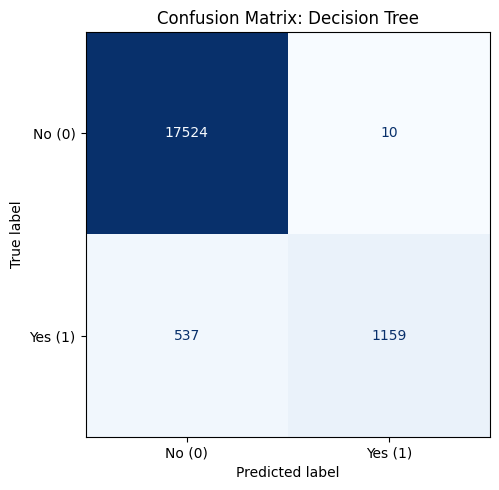

In [7]:
best_name = comparison_df.loc[0, 'Model']
best_pred = predictions[best_name]
print('Selected model:', best_name)
print('\nDetailed classification report:')
print(classification_report(y_test, best_pred, target_names=['No diabetes (0)', 'Diabetes (1)'], zero_division=0))

cm = confusion_matrix(y_test, best_pred, labels=[0, 1])
print('Confusion matrix [rows=actual, columns=predicted]:')
print(cm)
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No (0)', 'Yes (1)']).plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title(f'Confusion Matrix: {best_name}')
plt.tight_layout()
plt.show()

## 7. Conclusion (2–3 sentences)

In [8]:
best_row = comparison_df.iloc[0]
print(
    f"{best_name} was selected because it achieved the highest positive-class F1-score "
    f"({best_row['F1-score']:.4f}) among the three tested classifiers, with accuracy "
    f"{best_row['Accuracy']:.4f}, precision {best_row['Precision']:.4f}, and recall {best_row['Recall']:.4f}. "
    "F1-score was prioritized over accuracy because the classes are imbalanced, and the "
    "confusion matrix shows the false-positive and false-negative trade-off. "
    "These are held-out test results for an educational dataset, not evidence of clinical suitability."
)

Decision Tree was selected because it achieved the highest positive-class F1-score (0.8091) among the three tested classifiers, with accuracy 0.9716, precision 0.9914, and recall 0.6834. F1-score was prioritized over accuracy because the classes are imbalanced, and the confusion matrix shows the false-positive and false-negative trade-off. These are held-out test results for an educational dataset, not evidence of clinical suitability.


### Submission checklist

- [x] Trained **Logistic Regression**, **Decision Tree**, and **Random Forest**
- [x] Compared **Accuracy, Precision, Recall, F1-score**, plus optional **ROC-AUC**
- [x] Displayed **confusion matrix** of the highest-F1 model
- [x] Included a **2–3 sentence justification** generated using measured results

**Important:** Submit the `.ipynb` file with executed cell outputs visible. Keep the CSV available when running the notebook elsewhere.